In [1]:
print("Customer Churn Prediction")

Customer Churn Prediction


# Customer Churn Prediction Using Machine Learning

# Customer Churn Prediction Using Machine Learning

## 1. Introduction

Customer churn prediction is an important machine learning application in the telecommunications industry.

In this assignment, the Telco Customer Churn dataset is used to develop a machine learning system that predicts whether a customer is likely to leave the telecom company or remain with it.

The complete machine learning pipeline includes:

- Dataset loading and understanding
- Data preprocessing
- Exploratory Data Analysis
- Feature engineering
- Categorical data encoding
- Training and testing
- Machine learning model development
- Model evaluation
- Model comparison
- Customer churn prediction

The target variable in this project is Churn.

## 2. Objective

The main objective of this assignment is to build a complete customer churn prediction system using machine learning.

The specific objectives are:

1. Load and understand the Telco Customer Churn dataset.
2. Identify and handle missing and incorrect data.
3. Perform exploratory data analysis.
4. Identify important factors related to customer churn.
5. Prepare features for machine learning.
6. Train at least two classification models.
7. Evaluate the models using appropriate performance metrics.
8. Compare the trained models.
9. Select a final model based on the evaluation results.
10. Use the final model to predict churn for a sample customer.

## 3. Dataset Description

The dataset used in this project is:

WA_Fn-UseC_-Telco-Customer-Churn.csv

The dataset contains information about telecom customers, their services, account information, and whether they left the company.

The target variable is:

Churn

The target variable has two possible values:

- Yes → Customer left the company.
- No → Customer remained with the company.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [3]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [9]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [10]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [11]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

# 4. Data Preprocessing

Before training the machine learning models, the dataset was checked for:

- Missing values
- Duplicate records
- Incorrect data types
- Unnecessary columns
- Invalid values

In [12]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [14]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [15]:
df = df.dropna(subset=["TotalCharges"]).copy()

In [16]:
df = df.dropna(subset=["TotalCharges"]).copy()

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df = df.drop(columns=["customerID"])

# 5. Exploratory Data Analysis

Exploratory Data Analysis was performed to identify patterns and relationships between customer characteristics and churn.

The analysis focuses on:

1. Churn distribution
2. Contract type
3. Customer tenure
4. Monthly charges
5. Internet service
6. Payment method

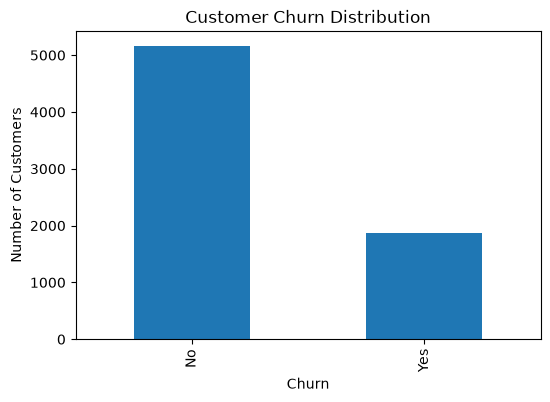

In [19]:
df["Churn"].value_counts().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

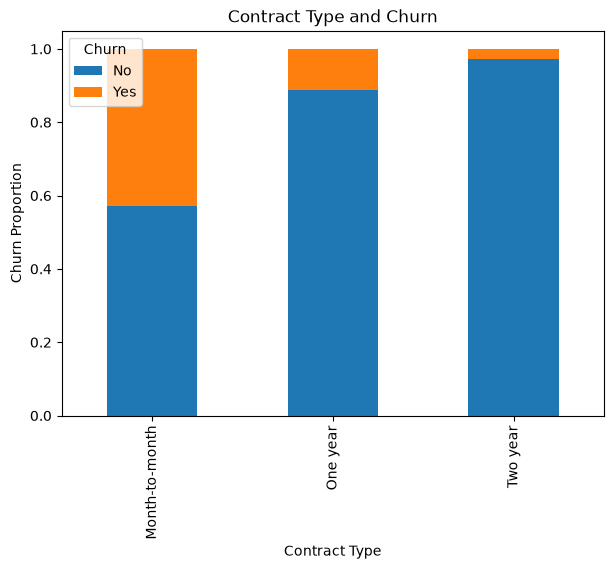

In [20]:
pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
).plot(
    kind="bar",
    stacked=True,
    figsize=(7,5)
)

plt.title("Contract Type and Churn")
plt.xlabel("Contract Type")
plt.ylabel("Churn Proportion")
plt.show()

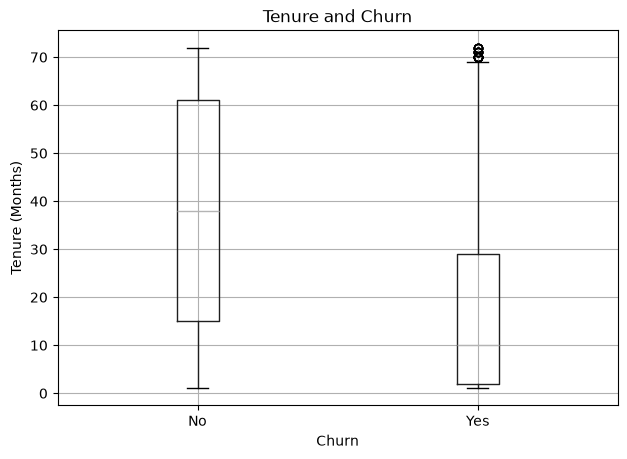

In [21]:
df.boxplot(
    column="tenure",
    by="Churn",
    figsize=(7,5)
)

plt.title("Tenure and Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

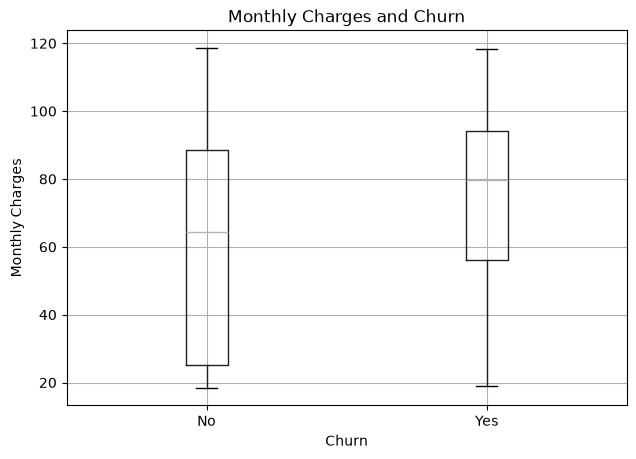

In [22]:
df.boxplot(
    column="MonthlyCharges",
    by="Churn",
    figsize=(7,5)
)

plt.title("Monthly Charges and Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

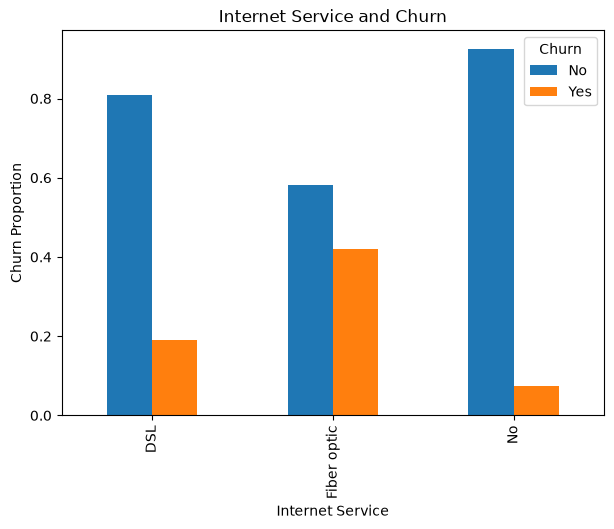

In [23]:
pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
).plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Internet Service and Churn")
plt.xlabel("Internet Service")
plt.ylabel("Churn Proportion")
plt.show()


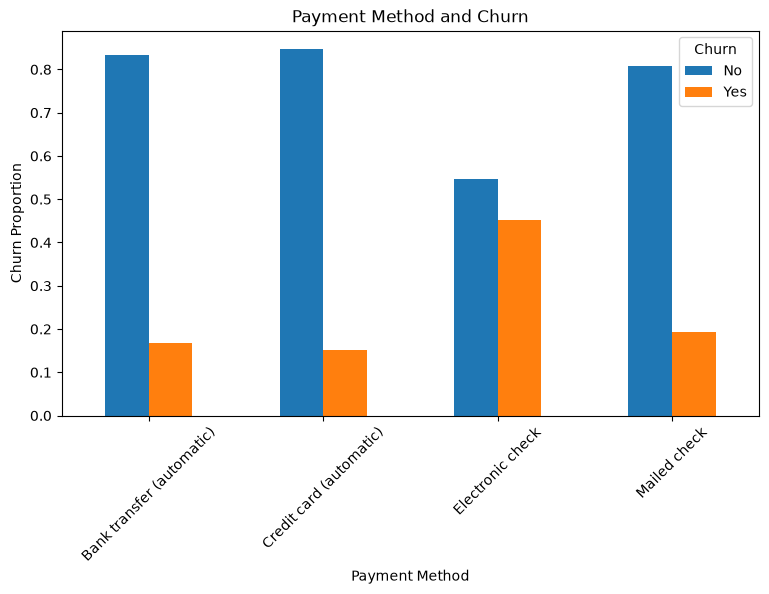

In [24]:
pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
).plot(
    kind="bar",
    figsize=(9,5)
)

plt.title("Payment Method and Churn")
plt.xlabel("Payment Method")
plt.ylabel("Churn Proportion")
plt.xticks(rotation=45)
plt.show()

# 6. Feature Engineering

The target variable was separated from the input features.

X represents the input features.

y represents the target variable.

In [25]:
X = df.drop(columns=["Churn"])
y = df["Churn"]

In [26]:
y = y.map({
    "No": 0,
    "Yes": 1
})

In [27]:
## 6.1 Categorical Feature Encoding

The dataset contains many categorical variables. These variables cannot be directly processed by most machine learning algorithms.

One-hot encoding was used to convert categorical variables into numerical features.

SyntaxError: invalid syntax (458512936.py, line 3)

## 6.1 Categorical Feature Encoding

The dataset contains many categorical variables. These variables cannot be directly processed by most machine learning algorithms.

One-hot encoding was used to convert categorical variables into numerical features.

In [28]:
X = pd.get_dummies(
    X,
    drop_first=True
)

X = X.astype(int)

In [29]:
X.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29,29,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56,1889,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53,108,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42,1840,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70,151,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


# 7. Training and Testing Split

The dataset was divided into training and testing sets using an 80:20 split.

The training set is used to train the models.

The testing set is used to evaluate the models on unseen data.

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [31]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5625, 30)
Testing data: (1407, 30)


# 8. Feature Scaling

Feature scaling was performed for Logistic Regression so that numerical features are placed on comparable scales.

In [32]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

# 9. Machine Learning Models

## 9.1 Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of a customer belonging to a particular class.

In this project, it predicts:

- Churn
- No Churn

In [33]:
logistic_model = LogisticRegression(
    max_iter=1000
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [34]:
y_pred_lr = logistic_model.predict(X_test_scaled)

In [35]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Logistic Regression")
print("Accuracy :", accuracy_lr)
print("Precision:", precision_lr)
print("Recall   :", recall_lr)
print("F1-Score :", f1_lr)

Logistic Regression
Accuracy : 0.8038379530916845
Precision: 0.6475903614457831
Recall   : 0.5748663101604278
F1-Score : 0.6090651558073654


In [36]:
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr
)

print(cm_lr)

[[916 117]
 [159 215]]


## 9.2 Decision Tree

A Decision Tree is a rule-based classification algorithm that makes predictions by splitting the dataset according to feature values.

In [37]:
decision_tree = DecisionTreeClassifier(
    random_state=42
)

decision_tree.fit(
    X_train,
    y_train
)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [38]:
y_pred_dt = decision_tree.predict(X_test)

In [39]:
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt)
recall_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Decision Tree")
print("Accuracy :", accuracy_dt)
print("Precision:", precision_dt)
print("Recall   :", recall_dt)
print("F1-Score :", f1_dt)

Decision Tree
Accuracy : 0.7093105899076049
Precision: 0.45430809399477806
Recall   : 0.46524064171123
F1-Score : 0.45970937912813736


In [40]:
cm_dt = confusion_matrix(
    y_test,
    y_pred_dt
)

print(cm_dt)

[[824 209]
 [200 174]]


# 10. Model Comparison

The two trained models were compared using Accuracy, Precision, Recall, and F1-Score.

In [41]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy_lr,
        accuracy_dt
    ],
    "Precision": [
        precision_lr,
        precision_dt
    ],
    "Recall": [
        recall_lr,
        recall_dt
    ],
    "F1-Score": [
        f1_lr,
        f1_dt
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.803838,0.647590,0.574866,0.609065
1,Decision Tree,0.709311,0.454308,0.465241,0.459709


# 11. Model Selection

The final model was selected based on the evaluation results obtained from the testing dataset.

Accuracy, Precision, Recall, and F1-Score were considered when comparing the two models.

The model with the stronger overall test-set performance was selected as the final model.

# 12. Application / Sample Prediction

The selected final model was used to make a prediction for a sample customer.

The model produces either:

- Churn
- No Churn

In [42]:
sample_customer = X_test.iloc[[0]]

In [43]:
sample_scaled = scaler.transform(sample_customer)

prediction = logistic_model.predict(sample_scaled)

if prediction[0] == 1:
    print("Prediction: Churn")
else:
    print("Prediction: No Churn")

Prediction: No Churn


# 13. Practical Application

A telecom company could integrate a churn prediction system into its customer analytics process.

The system could be used to:

- Identify customers with higher predicted churn risk.
- Analyze customer characteristics associated with churn.
- Support customer retention programs.
- Help customer service teams prioritize certain cases.
- Analyze contract and service-related churn patterns.
- Support data-driven customer management.

The model should be used as a decision-support tool rather than as the sole basis for customer actions.

# 14. Limitations

## 1. Historical Data

The model learns from historical customer records. Customer behavior can change over time.

## 2. Class Imbalance

The dataset contains more non-churn customers than churn customers. Therefore, accuracy alone does not provide a complete picture of model performance.

## 3. Limited Features

The dataset may not include all factors that influence churn, such as customer complaints, service quality, network performance, customer satisfaction, call-center interactions, and competitor offers.

## 4. Prediction Errors

Machine learning predictions are not always correct. Some customers predicted as churn may remain, while some customers predicted as non-churn may eventually leave.

# 15. Conclusion

This project successfully implemented a complete machine learning pipeline for customer churn prediction using the Telco Customer Churn dataset.

The dataset was loaded and examined using Pandas. Data preprocessing was performed to identify missing values, incorrect data types, duplicate records, and unnecessary columns.

The TotalCharges feature was converted into numeric format, and the customerID column was removed because it is an identifier rather than a useful predictive feature.

Exploratory Data Analysis was performed to investigate customer churn patterns based on contract type, tenure, monthly charges, internet service, and payment method.

Categorical variables were converted into numerical features using one-hot encoding. The data was divided into training and testing sets using an 80:20 split.

Two classification models, Logistic Regression and Decision Tree, were trained and evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

The final model was selected based on the obtained test-set results. The selected model was also applied to a sample customer to demonstrate how the system produces a Churn or No Churn prediction.

Overall, this project demonstrates how machine learning can be applied to customer data to identify patterns associated with telecom customer churn and support customer retention analysis.